P1 - IDIG4120 

Group members: Filza Akhlaq and Akanksha More

Submitted to: Steven Yves Le Moan

This notebook is divided in seven main sections as per the requirements of P2. 

Build a compression path you can explain completely, test it on data it has not seen, and account for every byte.
The aim is not a competitive compression ratio.

In [103]:
import matplotlib.pyplot as plt
import os
from pathlib import Path
from PIL import Image
import random
import numpy as np
from io import BytesIO

%load_ext autoreload
%autoreload 2
from codec import Codec, Transform, DCT, Quantisation, ZigZag, RLE

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. A lossless or lossy design with every stage named and justified.

Proposed compression: Lossy JPEG style compression, but doing it manually in this notebook.

The pipeline would look something like: Original RGB image → Compression → Decompression → Reconstructed RGB image

## In detail:


| Compression (Encoder) | Decompression (Decoder) |
|:---:|:---:|
| **Original RGB Image** | **Compressed Bytes + Metadata** |
| ↓ | ↓ |
| Separate RGB Channels | Entropy Decoding |
| ↓ | ↓ |
| Split into 8×8 Blocks (with padding if needed) | Reverse RLE + Zigzag |
| ↓ | ↓ |
| Apply DCT/PCA | Dequantise Coefficients |
| ↓ | ↓ |
| Quantise Coefficients | Apply Inverse DCT |
| ↓ | ↓ |
| Zigzag Ordering + RLE/Huffman | Reassemble Blocks and Remove Padding |
| ↓ | ↓ |
| Entropy Encoding | Combine RGB Channels |
| ↓ | ↓ |
| **Compressed Bytes + Metadata** | **Reconstructed RGB Image** |

**Note:** Our codec is lossy because quantisation removes some information. The reconstructed image will have the same dimensions and three colour channels as the original, but some pixel values may be different.


## Below code cell is using code from P1 to load the dataset

transistor
capsule
metal_nut
pill
hazelnut


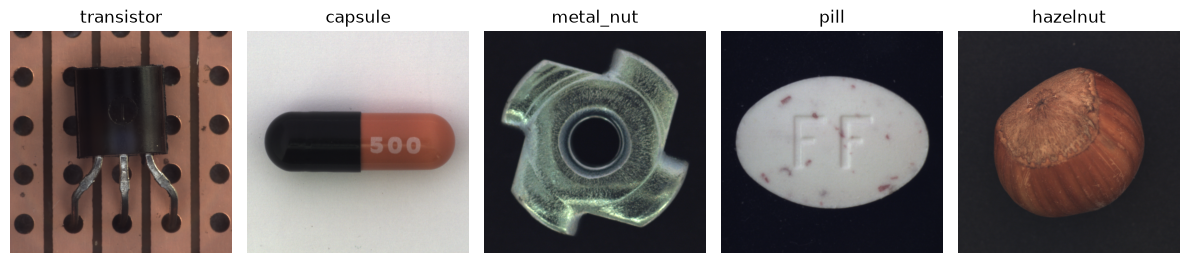

In [104]:
# creating a dictionary of images from the dataset and append the info such as
# filetype, shape, image size, datatype to each image
data_dict = {}
rdir = "../final_dataset"

for objecttype in os.listdir(rdir):
    object_path = Path(rdir) / objecttype

    # Skip files which are not directories
    if not object_path.is_dir():
        continue

    object_dir = object_path / 'train'
    print(objecttype)

    for imgpath in object_dir.iterdir():
        if not imgpath.is_file():
            continue

        if objecttype not in data_dict:
            data_dict[objecttype] = []

        img = Image.open(imgpath)
        img_np = np.array(img)

        data_dict[objecttype].append((
            imgpath,
            imgpath.suffix,
            img_np.shape,
            imgpath.stat().st_size,
            img_np.dtype
        ))

# function to get a random image from the dataset
def get_one_random_image(data_dict, objecttype:str = None) -> Path:
    objtype = objecttype or random.choice(list(data_dict.keys()))
    return random.choice(data_dict[objtype])

# A function that displays images with different parameters such as axes, title, label
def display_image(img, cmap: str = None, title: str = None, 
                  axes: bool = True, figsize=(4, 4),
                  xlabel: str = None, ylabel: str = None, xticks: list = None, yticks: list = None, ax=None):
    
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
        
    ax.imshow(img, cmap=cmap)

    if title is not None:
        ax.set_title(title)

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    if not axes:
        ax.axis('off')
        
    if xticks is not None:
        ax.set_xticks(xticks)
        
    if yticks is not None:
        ax.set_yticks(yticks)
        
    return ax


# using the loader created in P1

fig, axes = plt.subplots(1, len(data_dict), figsize=(12, 3))

for ax, objecttype in zip(axes, data_dict):
    obj = get_one_random_image(data_dict, objecttype)
    imgpath = obj[0]

    img = Image.open(imgpath)

    display_image(img, title=objecttype, axes=False, ax=ax)

plt.tight_layout()
plt.show()

## Step-1 Prepare Image for Compression

In [105]:
# Select one image for testing our codec
objecttype = "capsule"

obj = get_one_random_image(data_dict, objecttype)
imgpath = obj[0]

# Convert to RGB and NumPy array
img = Image.open(imgpath).convert("RGB")
image_array = np.array(img)

print("Image:", imgpath.name)
print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Original file size:", imgpath.stat().st_size, "bytes")
print("Raw image size:", image_array.nbytes, "bytes")

Image: 154.png
Shape: (1000, 1000, 3)
Data type: uint8
Original file size: 1117024 bytes
Raw image size: 3000000 bytes


As we can see the raw image size is 3000000 bytes however PNG image size is 1140691 bytes, this is because PNG uses a losless compression.

## Step-2 Separate the RGB Channels

In [106]:
# Separate the RGB image into three channels
red = image_array[:, :, 0]
green = image_array[:, :, 1]
blue = image_array[:, :, 2]

print("Red channel:", red.shape)
print("Green channel:", green.shape)
print("Blue channel:", blue.shape)

Red channel: (1000, 1000)
Green channel: (1000, 1000)
Blue channel: (1000, 1000)


Notice that this image dimensions are 1000 × 1000, and 1000 is divisible by 8. That means this particular image won't need padding when we divide it into 8×8 blocks. However, our final codec should still handle images with other dimensions.

## Step-3 Divide each channel into 8x8 blocks

In [107]:
block_size = 8
rgb_blocks = {}

for channel_name, channel in zip(["Red", "Green", "Blue"], [red, green, blue]):
    blocks = []

    for row in range(0, channel.shape[0], block_size):
        for col in range(0, channel.shape[1], block_size):
            block = channel[row:row+8, col:col+8]
            blocks.append(block)

    rgb_blocks[channel_name] = np.array(blocks)

    print(f"{channel_name}: {rgb_blocks[channel_name].shape}")

Red: (15625, 8, 8)
Green: (15625, 8, 8)
Blue: (15625, 8, 8)


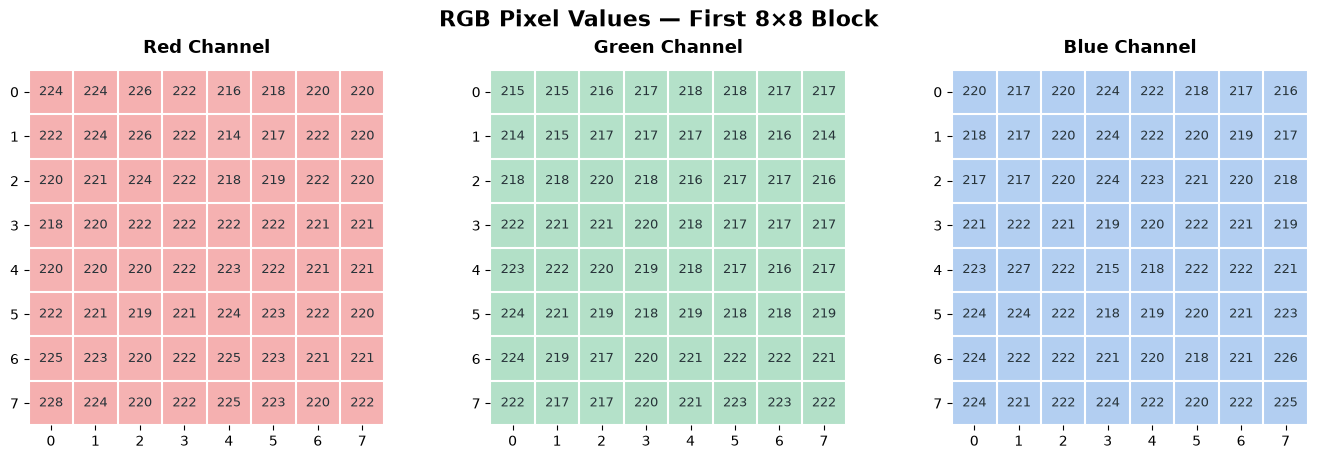

In [108]:

from matplotlib.colors import LinearSegmentedColormap

colors = {
    "Red": ["#FFFFFF", "#F4A6A6"],
    "Green": ["#FFFFFF", "#A8DCC0"],
    "Blue": ["#FFFFFF", "#A8C8F0"]
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

for ax, (channel_name, blocks) in zip(axes, rgb_blocks.items()):
    block = blocks[0]

    cmap = LinearSegmentedColormap.from_list(
        channel_name, colors[channel_name]
    )

    # Displaying heatmap
    ax.imshow(block, cmap=cmap, vmin=0, vmax=255)

    # Add the pixel values
    for row in range(8):
        for col in range(8):
            ax.text(
                col, row, str(block[row, col]),
                ha="center", va="center",
                fontsize=9, color="#263238"
            )

    # Adding grid lines
    ax.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_title(
        f"{channel_name} Channel",
        fontsize=13, fontweight="bold", pad=12
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "RGB Pixel Values — First 8×8 Block",
    fontsize=16, fontweight="bold"
)

plt.tight_layout()
plt.show()


## Step-4 Applying DCT

Trying DCT on first block first

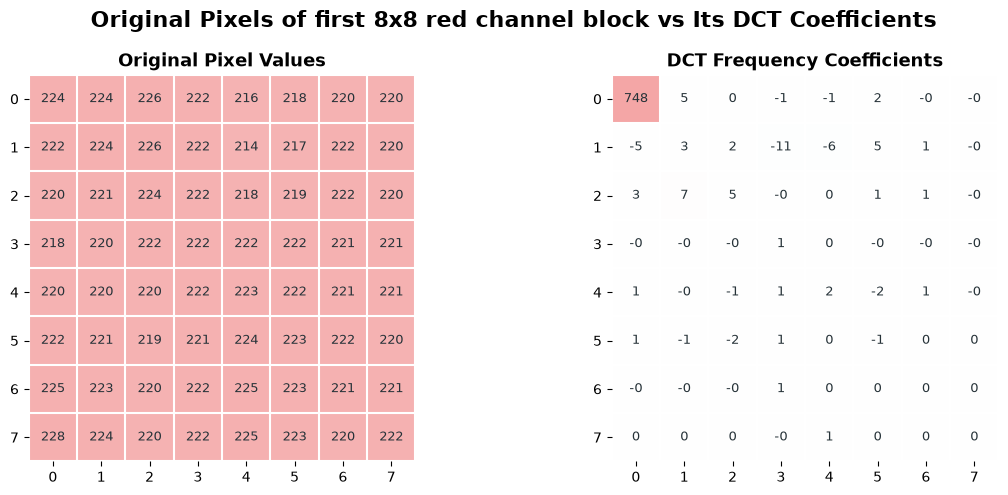

In [109]:

from scipy.fft import dctn
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Select the first 8x8 block from the red channel
block = rgb_blocks["Red"][0]

# Apply DCT
shifted_block = block.astype(np.float64) - 128
dct_block = dctn(shifted_block, norm="ortho")

# Create soft pastel colour maps
pixel_cmap = LinearSegmentedColormap.from_list(
    "PastelRed", ["#FFFFFF", "#F4A6A6"]
)

dct_cmap = LinearSegmentedColormap.from_list(
    "PastelDCT", ["#A8C8F0", "#FFFFFF", "#F4A6A6"]
)

# Create visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(block, cmap=pixel_cmap, vmin=0, vmax=255)
axes[0].set_title("Original Pixel Values", fontsize=13, fontweight="bold")

max_abs = np.max(np.abs(dct_block))
axes[1].imshow(
    dct_block,
    cmap=dct_cmap,
    norm=TwoSlopeNorm(vcenter=0, vmin=-max_abs, vmax=max_abs)
)
axes[1].set_title("DCT Frequency Coefficients", fontsize=13, fontweight="bold")

# Add values and grid lines
for ax, data in zip(axes, [block, dct_block]):
    for row in range(8):
        for col in range(8):
            ax.text(
                col, row, f"{data[row, col]:.0f}",
                ha="center", va="center",
                fontsize=9, color="#263238"
            )

    ax.set_xticks(range(8))
    ax.set_yticks(range(8))

    ax.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    "Original Pixels of first 8x8 red channel block vs Its DCT Coefficients",
    fontsize=16, fontweight="bold"
)

plt.tight_layout()
plt.show()


## Step-5 Quantisation

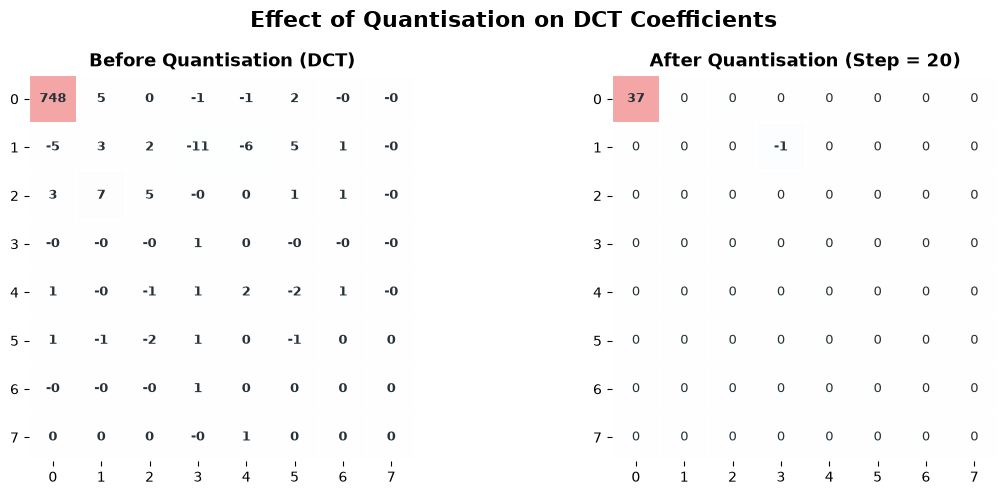

Zero coefficients: 62/64
Percentage of zeros: 96.9%


In [110]:
# Apply quantisation to the DCT block
q_step = 20
quantised_block = np.round(dct_block / q_step).astype(int)

from matplotlib.colors import LinearSegmentedColormap

# Pastel colour map
cmap = LinearSegmentedColormap.from_list(
    "PastelDCT", ["#A8C8F0", "#FFFFFF", "#F4A6A6"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

data_list = [dct_block, quantised_block]
titles = ["Before Quantisation (DCT)", "After Quantisation (Step = 20)"]

for ax, data, title in zip(axes, data_list, titles):

    # Use symmetric colour limits around zero
    limit = max(np.max(np.abs(data)), 1)

    ax.imshow(data, cmap=cmap, vmin=-limit, vmax=limit)

    # Display coefficient values
    for row in range(8):
        for col in range(8):
            value = data[row, col]

            ax.text(
                col, row,
                f"{value:.0f}",
                ha="center", va="center",
                fontsize=9,
                color="#263238",
                fontweight="bold" if value != 0 else "normal"
            )

    # Grid and labels
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_title(title, fontsize=13, fontweight="bold")

    for spine in ax.spines.values():
        spine.set_visible(False)

plt.suptitle(
    "Effect of Quantisation on DCT Coefficients",
    fontsize=16, fontweight="bold"
)

plt.tight_layout()
plt.show()

# Summary
zero_count = np.count_nonzero(quantised_block == 0)
total = quantised_block.size

print(f"Zero coefficients: {zero_count}/{total}")
print(f"Percentage of zeros: {zero_count / total * 100:.1f}%")


## Step-6 Zigzag Ordering

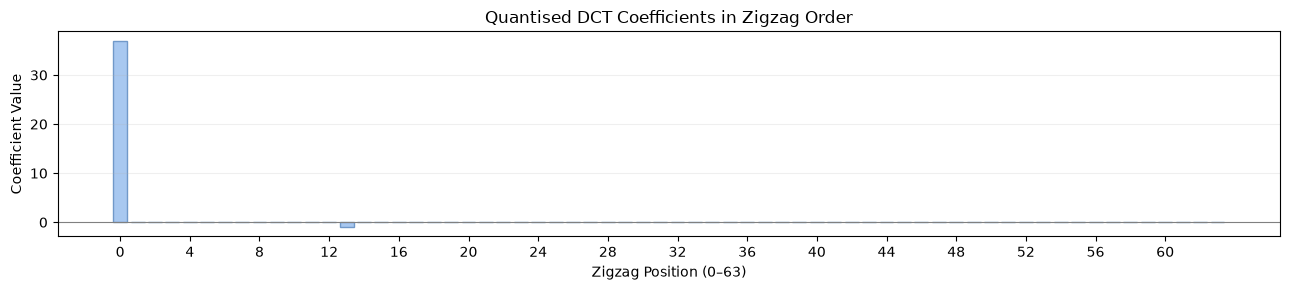

In [111]:

# Generate zigzag indices for an 8x8 block
def zigzag_indices(n=8):
    indices = []

    for diagonal in range(2 * n - 1):
        cells = []

        for row in range(n):
            col = diagonal - row

            if 0 <= col < n:
                cells.append((row, col))

        if diagonal % 2 == 0:
            cells.reverse()

        indices.extend(cells)

    return indices


# Convert the quantised block into a 1D sequence
indices = zigzag_indices()
zigzag_values = np.array([
    quantised_block[row, col]
    for row, col in indices
])

# Visualise the zigzag sequence
fig, ax = plt.subplots(figsize=(13, 3))

ax.bar(
    range(64),
    zigzag_values,
    color="#A8C8F0",
    edgecolor="#7199C9"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Quantised DCT Coefficients in Zigzag Order")
ax.set_xlabel("Zigzag Position (0–63)")
ax.set_ylabel("Coefficient Value")
ax.set_xticks(range(0, 64, 4))
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


## Step-7 RLE

In [112]:

def rle_encode(values):
    encoded = []
    zero_count = 0

    for value in values:
        value = int(value)

        if value == 0:
            zero_count += 1
        else:
            encoded.append((zero_count, value))
            zero_count = 0

    # Record remaining zeros at the end
    encoded.append((zero_count, None))

    return encoded


# Apply RLE to our zigzag sequence
rle_result = rle_encode(zigzag_values)

print("Original coefficients:", len(zigzag_values))
print("RLE entries:", len(rle_result))
print("Encoded representation:", rle_result)


Original coefficients: 64
RLE entries: 3
Encoded representation: [(0, 37), (12, -1), (50, None)]


## Step-8 Encoding the entire 1000x1000 image and writing into a JSON file

In [113]:

from scipy.fft import dctn

q_step = 20
indices = zigzag_indices(8)

# Store encoded blocks for each colour channel
encoded_image = {}

for channel_name, blocks in rgb_blocks.items():

    encoded_blocks = []

    for block in blocks:

        # 1. Shift pixel values
        shifted = block.astype(np.float64) - 128

        # 2. Apply 2D DCT
        coefficients = dctn(shifted, norm="ortho")

        # 3. Quantisation
        quantised = np.round(coefficients / q_step).astype(int)

        # 4. Zigzag ordering
        zigzag = [
            int(quantised[row, col])
            for row, col in indices
        ]

        # 5. Run-length encoding
        encoded = rle_encode(zigzag)

        encoded_blocks.append(encoded)

    encoded_image[channel_name] = encoded_blocks

    print(f"{channel_name}: {len(encoded_blocks)} blocks encoded")


Red: 15625 blocks encoded
Green: 15625 blocks encoded
Blue: 15625 blocks encoded


Visualizing the encoded results

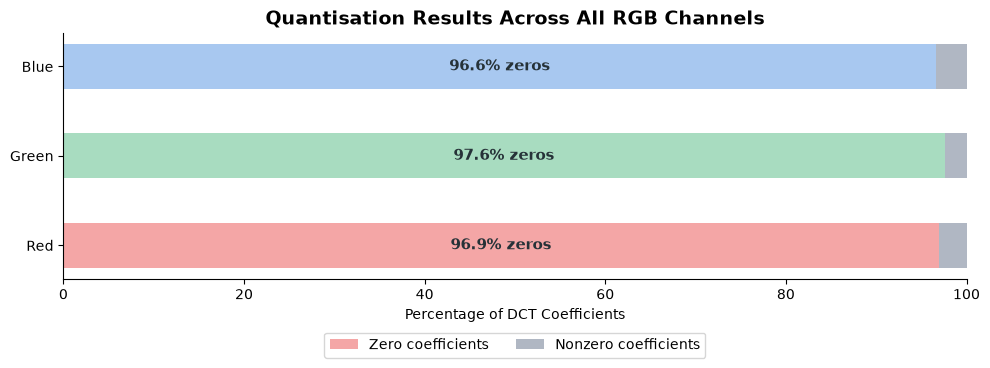

In [114]:
# Count zero and nonzero coefficients represented by RLE
channel_names = []
zero_counts = []
nonzero_counts = []

for channel_name, blocks in encoded_image.items():

    zeros = 0
    nonzeros = 0

    for block in blocks:
        for zero_run, value in block:
            zeros += zero_run

            if value is not None:
                nonzeros += 1

    channel_names.append(channel_name)
    zero_counts.append(zeros)
    nonzero_counts.append(nonzeros)

# Calculate percentages
totals = np.array(zero_counts) + np.array(nonzero_counts)
zero_pct = np.array(zero_counts) / totals * 100
nonzero_pct = np.array(nonzero_counts) / totals * 100

# Visualise
fig, ax = plt.subplots(figsize=(10, 4))

colors = ["#F4A6A6", "#A8DCC0", "#A8C8F0"]

for i, channel in enumerate(channel_names):
    ax.barh(
        channel, zero_pct[i],
        color=colors[i], height=0.5,
        label="Zero coefficients" if i == 0 else None
    )

    ax.barh(
        channel, nonzero_pct[i],
        left=zero_pct[i],
        color="#B0B7C3", height=0.5,
        label="Nonzero coefficients" if i == 0 else None
    )

    ax.text(
        zero_pct[i] / 2, i,
        f"{zero_pct[i]:.1f}% zeros",
        ha="center", va="center",
        fontsize=11, fontweight="bold",
        color="#263238"
    )

ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of DCT Coefficients")
ax.set_title(
    "Quantisation Results Across All RGB Channels",
    fontsize=14, fontweight="bold"
)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.35), ncol=2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


Converting our RLE data into actual compressed bytes


In [115]:
# Final encoded representation
compressed = encoded_image

print("Number of encoded blocks:")
for channel, blocks in compressed.items():
    print(f"{channel}: {len(blocks)} blocks")

print("\nExample encoded block:")
print(compressed["Red"][0])

Number of encoded blocks:
Red: 15625 blocks
Green: 15625 blocks
Blue: 15625 blocks

Example encoded block:
[(0, 37), (12, -1), (50, None)]


Writing the results into a JSON file

In [116]:
import json

# Package encoded data with information needed for decoding
codec_data = {
    "metadata": {
        "height": image_array.shape[0],
        "width": image_array.shape[1],
        "channels": 3,
        "block_size": 8,
        "q_step": q_step,
        "dtype": "uint8",
        "channel_order": ["Red", "Green", "Blue"],
        "rle_format": "zero_count, value; None marks end of block"
    },
    "encoded_blocks": encoded_image
}

# Save encoded data
output_file = "encoded_image.json"

with open(output_file, "w") as f:
    json.dump(codec_data, f)

print(f"Encoded image saved to: {output_file}")


Encoded image saved to: encoded_image.json


In [117]:
#Decoder can use this to get the data from file
import json

with open("encoded_image.json", "r") as f:
    codec_data = json.load(f)

metadata = codec_data["metadata"]
encoded_blocks = codec_data["encoded_blocks"]

print(metadata)
print(encoded_blocks["Red"][0])

{'height': 1000, 'width': 1000, 'channels': 3, 'block_size': 8, 'q_step': 20, 'dtype': 'uint8', 'channel_order': ['Red', 'Green', 'Blue'], 'rle_format': 'zero_count, value; None marks end of block'}
[[0, 37], [12, -1], [50, None]]


In [118]:
# checking the actual file size
import os

original_size = image_array.nbytes
encoded_size = os.path.getsize("encoded_image.json")

print(f"Original raw RGB size: {original_size:,} bytes")
print(f"Encoded JSON file size: {encoded_size:,} bytes")
print(f"Size ratio: {original_size / encoded_size:.2f}:1")

Original raw RGB size: 3,000,000 bytes
Encoded JSON file size: 1,443,302 bytes
Size ratio: 2.08:1


## Final Encoder — compress() Function
The previous steps demonstrate the encoding process individually.
This function combines all stages into a reusable encoder.

It also adds padding when image dimensions are not divisible by 8
and stores the metadata required for decoding.

In [119]:
import numpy as np
import json
from scipy.fft import dctn
from pathlib import Path

def compress(image, settings=None, output_file=None, input_path=None):

    if settings is None:
        settings = {"q_step": 20}

    q_step = settings["q_step"]
    block_size = 8

    # Validate input
    image = np.asarray(image)

    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Input must be an RGB image")

    if image.dtype != np.uint8:
        raise ValueError("Input must have dtype uint8")

    if image.shape[0] == 0 or image.shape[1] == 0:
        raise ValueError("Image must not be empty")

    if not isinstance(q_step, (int, float)) or not np.isfinite(q_step) or q_step <= 0:
        raise ValueError("q_step must be a positive finite number")

    height, width, channels = image.shape

    # Calculate padding
    pad_h = (block_size - height % block_size) % block_size
    pad_w = (block_size - width % block_size) % block_size

    # Pad image to multiples of 8
    padded_image = np.pad(
        image,
        ((0, pad_h), (0, pad_w), (0, 0)),
        mode="edge"
    )

    encoded_image = {}
    channel_names = ["Red", "Green", "Blue"]
    indices = zigzag_indices(block_size)

    for channel_index, channel_name in enumerate(channel_names):

        channel = padded_image[:, :, channel_index]
        encoded_blocks = []

        for row in range(0, channel.shape[0], block_size):
            for col in range(0, channel.shape[1], block_size):

                # Extract 8x8 block
                block = channel[
                    row:row + block_size,
                    col:col + block_size
                ]

                # DCT
                shifted = block.astype(np.float64) - 128
                dct_block = dctn(shifted, norm="ortho")

                # Quantisation
                quantised = np.rint(dct_block / q_step).astype(int)

                # Zigzag
                zigzag = [
                    int(quantised[r, c])
                    for r, c in indices
                ]

                # Run-Length Encoding
                encoded_blocks.append(rle_encode(zigzag))

        encoded_image[channel_name] = encoded_blocks

    # Package data and metadata
    compressed = {
        "metadata": {
            "height": height,
            "width": width,
            "channels": channels,
            "block_size": block_size,
            "q_step": q_step,
            "pad_h": pad_h,
            "pad_w": pad_w,
            "dtype": "uint8",
            "channel_order": channel_names,
            "rle_format": "zero_count, value; None marks end of block"
        },
        "encoded_blocks": encoded_image
    }

    # Create a separate folder for encoded files
    output_dir = Path("encoded_outputs")
    output_dir.mkdir(parents=True, exist_ok=True)

    # Generate output filename
    if output_file is None:
        if input_path is not None:
            output_file = f"{Path(input_path).stem}_encoded.json"
        else:
            output_file = "encoded_image.json"

    # Save inside encoded_outputs folder
    output_file = output_dir / Path(output_file).name

    # Save encoded data
    with open(output_file, "w") as f:
        json.dump(compressed, f)

    print(f"Encoded image saved to: {output_file}")

    return compressed


In [120]:
# Select an image
obj = get_one_random_image(data_dict, "pill")
imgpath = obj[0]

# Load the SAME image that we are encoding
img = Image.open(imgpath).convert("RGB")
image_array = np.array(img)

# Encode the image
compressed = compress(
    image_array,
    settings={"q_step": 20},
    input_path=imgpath
)

print("Original image:", imgpath.name)
print("Original shape:", image_array.shape)

Encoded image saved to: encoded_outputs/041_encoded.json
Original image: 041.png
Original shape: (800, 800, 3)


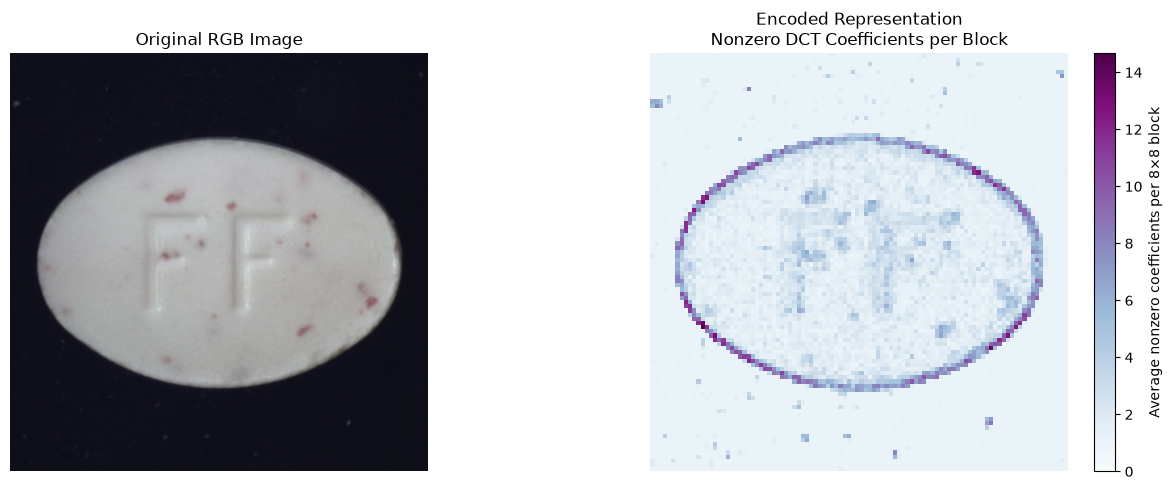

In [121]:
#visualizing the compress process
import matplotlib.pyplot as plt
import numpy as np

# Get metadata
metadata = compressed["metadata"]
block_size = metadata["block_size"]

padded_h = metadata["height"] + metadata["pad_h"]
padded_w = metadata["width"] + metadata["pad_w"]

blocks_h = padded_h // block_size
blocks_w = padded_w // block_size

# Count nonzero coefficients in each encoded block
activity = np.zeros((blocks_h, blocks_w))

for channel in ["Red", "Green", "Blue"]:
    blocks = compressed["encoded_blocks"][channel]

    for i, block in enumerate(blocks):
        nonzero = sum(value is not None for _, value in block)
        activity.flat[i] += nonzero

# Average across RGB channels
activity /= 3

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(image_array)
axes[0].set_title("Original RGB Image")
axes[0].axis("off")

im = axes[1].imshow(
    activity,
    cmap="BuPu",
    vmin=0,
    vmax=np.max(activity)
)
axes[1].set_title("Encoded Representation\nNonzero DCT Coefficients per Block")
axes[1].axis("off")

fig.colorbar(
    im, ax=axes[1],
    label="Average nonzero coefficients per 8×8 block",
    fraction=0.046,
    pad=0.04
)

plt.tight_layout()
plt.show()


# 2. Tests for shape, data type, empty and tiny inputs, and one unseen file.

# 3. A genuine byte count, or a defined coded-bit estimate that includes the side information.

# 4. Lossless: exact round-trip tests. Lossy: a rate–quality curve with a named metric.

We use the q_step knob for the rate-quality analysis. We use following values for q_step:

q_step = [8,32,64,128,256]

We pick one image, apply compression and then decompression to it by configuring q_step to above values. We then anaylse the image quality visually, and by using measures like MSE and PSNR, and compare it against the atorage bits.

<Axes: title={'center': 'Original image'}>

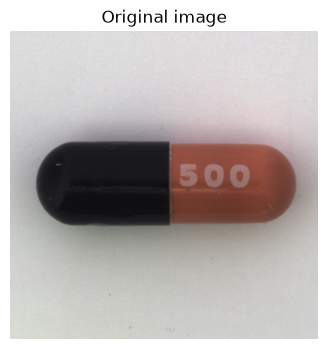

In [122]:
# Select one image for testing our codec
objecttype = "capsule"

obj = get_one_random_image(data_dict, objecttype)
imgpath = obj[0]

# Convert to RGB and NumPy array
img = Image.open(imgpath).convert("RGB")
image_array = np.array(img)

original_png_size_bytes = Path(imgpath).stat().st_size
original_size_bytes = image_array.nbytes

display_image(img, title="Original image", axes=False)

In [ ]:
# function to calculate mean squared error
def calc_mse(original, decompressed):
    diff = original.astype(np.float64) - decompressed.astype(np.float64)
    
    mse = np.mean(diff ** 2)
    
    return mse

# function to calculate psnr
def calc_psnr(original, decompressed):

    mse = calc_mse(original, decompressed)
    
    if mse == 0:
        return np.inf
    
    return 10 * np.log10(255**2 / mse)
    
    

Encoded image saved to: compressed/compressed_image_1_sec4.json
q_step = 8 | Orignal 3,000,000 bytes | Stored 3,024,222 bytes | 24.194 bits per pixel | Mean Squared error = 2.541 bpp | PSNR = 44.08 dB | Compression ratio = 0.99 dB


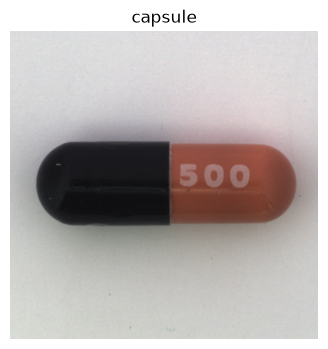

Encoded image saved to: compressed/compressed_image_2_sec4.json
q_step =32 | Orignal 3,000,000 bytes | Stored 970,110 bytes | 7.761 bits per pixel | Mean Squared error = 8.892 bpp | PSNR = 38.64 dB | Compression ratio = 3.09 dB


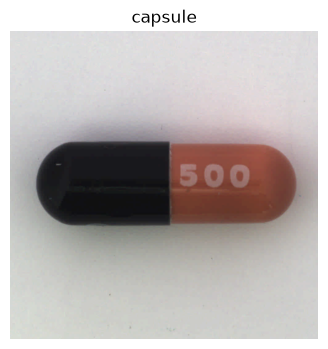

Encoded image saved to: compressed/compressed_image_3_sec4.json
q_step =64 | Orignal 3,000,000 bytes | Stored 894,107 bytes | 7.153 bits per pixel | Mean Squared error = 14.169 bpp | PSNR = 36.62 dB | Compression ratio = 3.36 dB


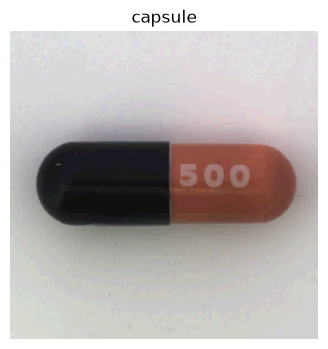

Encoded image saved to: compressed/compressed_image_4_sec4.json
q_step =128 | Orignal 3,000,000 bytes | Stored 855,843 bytes | 6.847 bits per pixel | Mean Squared error = 30.723 bpp | PSNR = 33.26 dB | Compression ratio = 3.51 dB


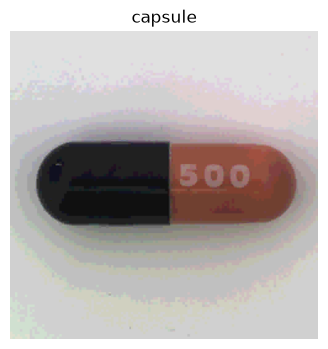

Encoded image saved to: compressed/compressed_image_5_sec4.json
q_step =256 | Orignal 3,000,000 bytes | Stored 841,110 bytes | 6.729 bits per pixel | Mean Squared error = 96.977 bpp | PSNR = 28.26 dB | Compression ratio = 3.57 dB


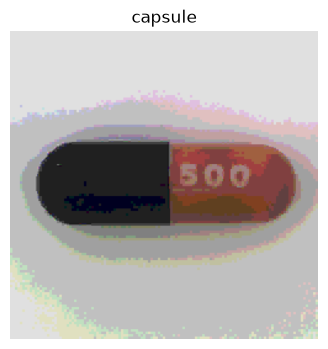

In [ ]:
q_steps = [8,32,64,128,256]

count =1
height , width = image_array.shape[:2]

stats = []
for q_step in q_steps:
    # initialize the codec with q_step
    codec = Codec(stages= [DCT(), Quantisation(q_steps=q_step), ZigZag(), RLE()])
    
    # Apply compression
    filename = f'compressed_image_{count}_sec4.json'
    compressed_image = codec.compress(img, output_file=filename)
    count += 1
    
    # Apply decompression
    decompressed_image = codec.decompress(compressed_image)
    
    stored_size_bytes = (codec.output_dir / filename).stat().st_size
    
    compression_ratio = original_size_bytes / stored_size_bytes
    
    # bit per pixel (rate)
    bits_per_pixel = (stored_size_bytes * 8) / (height * width)
    
    # calculate mse and psnr
    mse = calc_mse(image_array, decompressed_image)
    psnr = calc_psnr(image_array, decompressed_image)
    
    stats.append({'q_step': q_step,'size_bytes': stored_size_bytes, 'bits_per_pixel': bits_per_pixel, "mse": mse, "psnr": psnr, "compression ratio": compression_ratio})
    
    print(
        f"q_step ={ q_step:2d} | "
        f"Orignal {original_size_bytes:,} bytes | "
        f"Stored {stored_size_bytes:,} bytes | "
        f"{bits_per_pixel:.3f} bits per pixel | "
        f"Mean Squared error = {mse:.3f} bpp | "
        f"PSNR = {psnr:.2f} dB | "
        f"Compression ratio = {compression_ratio:.2f} dB"
    )
    display_image(decompressed_image, title=objecttype, axes=False)
    plt.show()
    
    
    

From above images, we can observe the tradeoff between quality and stored number bytes as we increase the q_step.

When q_step = 8, there is not noticeable change in image quality, however the bits per pixel is very high, and in fact the stored image size is more than the raw image.

When q_step = 32, there is still not noticebale change in image quality, but the bits per pixel are significantly low with much better storage.

For q_step = 64 and above, we can start observing noticebale artefacts in image, the bits per pixel is decreasing but the decrease in quality of image more significant. 

So it is safe to say by observing images, q_step=32 is a good benchmark.


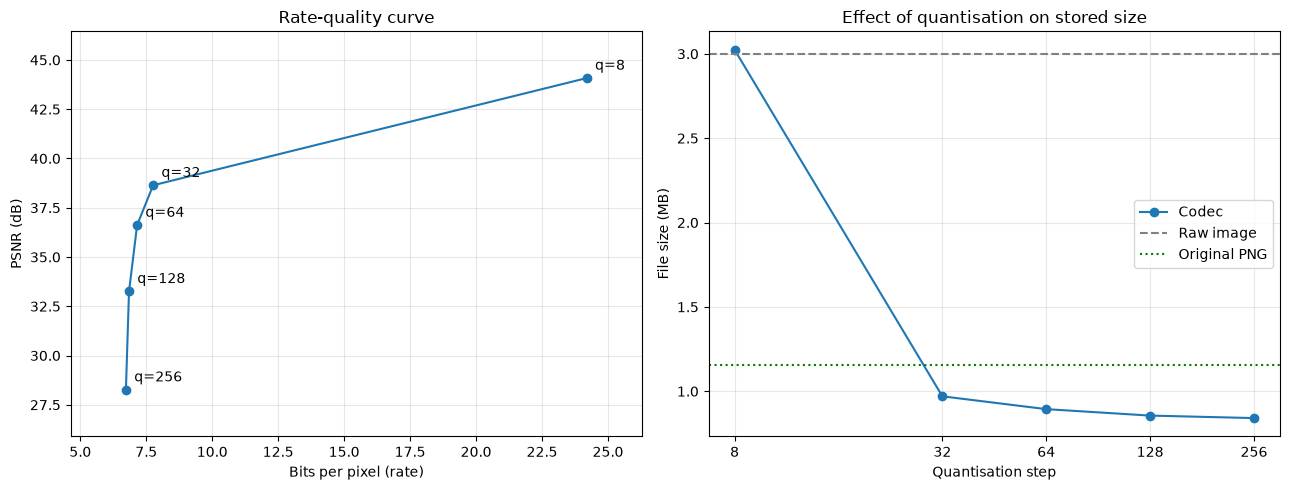

In [ ]:
results = sorted(stats, key=lambda result: result["q_step"])

q_values = np.array([result["q_step"] for result in results])
sizes = np.array([result["size_bytes"] for result in results])
rates = np.array([result["bits_per_pixel"] for result in results])
psnr_values = np.array([result["psnr"] for result in results])


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# rate–quality curve
order = np.argsort(rates)

axes[0].plot(rates[order], psnr_values[order], "o-")

for q, rate, quality in zip(q_values, rates, psnr_values):
    axes[0].annotate(
        f"q={q}",
        (rate, quality),
        xytext=(6, 6),
        textcoords="offset points",
    )

axes[0].set(
    xlabel="Bits per pixel (rate)",
    ylabel="PSNR (dB)",
    title="Rate-quality curve",
)
axes[0].margins(x=0.12, y=0.15)

# stored size versus quantisation step
axes[1].plot(
    q_values, sizes / 1_000_000,
    "o-", label="Codec",
)
axes[1].axhline(
    original_size_bytes / 1_000_000,
    color="gray", linestyle="--", label="Raw image",
)
axes[1].axhline(
    original_png_size_bytes / 1_000_000,
    color="green", linestyle=":", label="Original PNG",
)

axes[1].set_xscale("log", base=2)
axes[1].set_xticks(q_values)
axes[1].set_xticklabels([str(q) for q in q_values])
axes[1].set(
    xlabel="Quantisation step",
    ylabel="File size (MB)",
    title="Effect of quantisation on stored size",
)
axes[1].legend()

for axis in axes:
    axis.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. A comparison against one baseline, at comparable settings.

Here, we set q_step = 32, and compress a image using our Codec. We compare the result with Pillow's JPEG encoder.

In [ ]:
q_step = 32
src_image = img

# get stats for q_step=32
codec_result = next(
    result for result in stats 
    if result['q_step'] == q_step
    )

target_psnr = codec_result['psnr']

jpeg_stats = []

# perform image compression using JPEG pipeline from quality=1 to quality=98
for quality in range(1, 98):
    with BytesIO() as buffer:
        src_image.save(
            buffer,
            format="JPEG",
            quality=quality,
            subsampling=0,
            optimize=True,
            progressive=False,
        )
        
        stored_size_bytes = buffer.tell()
        
        buffer.seek(0)
        
        with Image.open(buffer) as decoded:
            decompressed_image = np.array(decoded.convert("RGB"))
    
    bits_per_pixel = stored_size_bytes * 8 / (height*width) 
    mse = calc_mse(image_array, decompressed_image)
    psnr = calc_psnr(image_array, decompressed_image)   
    compression_ratio = original_size_bytes/stored_size_bytes
    
    jpeg_stats.append({
        "quality": quality,
        "size_bytes": stored_size_bytes,
        "bits_per_pixel": bits_per_pixel,
        "msr": mse,
        "psnr": psnr
    })

# find the quality setting for jpeg pipeline whose resulting psnr is close to the psnr obtained using q_step=32 in our codec 
closest_jpeg = min(jpeg_stats, key=lambda result: abs(codec_result['psnr']-target_psnr),)

comparison = [
    ("Our codec", f"q_step={q_step}", codec_result),
    ("JPEG", f"quality={closest_jpeg['quality']}", closest_jpeg),
]

for name, setting, result in comparison:
    print(
        f"{name} ({setting}) | "
        f"PSNR: {result['psnr']:.2f} dB | "
        f"Size: {result['size_bytes']:,} bytes | "
        f"Rate: {result['bits_per_pixel']:.3f} bpp"
    )
   
psnr_gap = abs(closest_jpeg["psnr"] - target_psnr)
size_ratio = codec_result["size_bytes"] / closest_jpeg["size_bytes"]

print(f"\nAbsolute PSNR difference: {psnr_gap:.3f} dB")
print(f"Within chosen 0.5 dB tolerance: {psnr_gap <= 0.5}")
print(f"Ratio of Our codec and JPEG size {size_ratio:.2f}x")

Our codec (q_step=32) | PSNR: 38.64 dB | Size: 970,110 bytes | Rate: 7.761 bpp
JPEG (quality=1) | PSNR: 27.08 dB | Size: 12,329 bytes | Rate: 0.099 bpp

Absolute PSNR difference: 11.561 dB
Within chosen 0.5 dB tolerance: False
Ratio of Our codec and JPEG size 78.69x


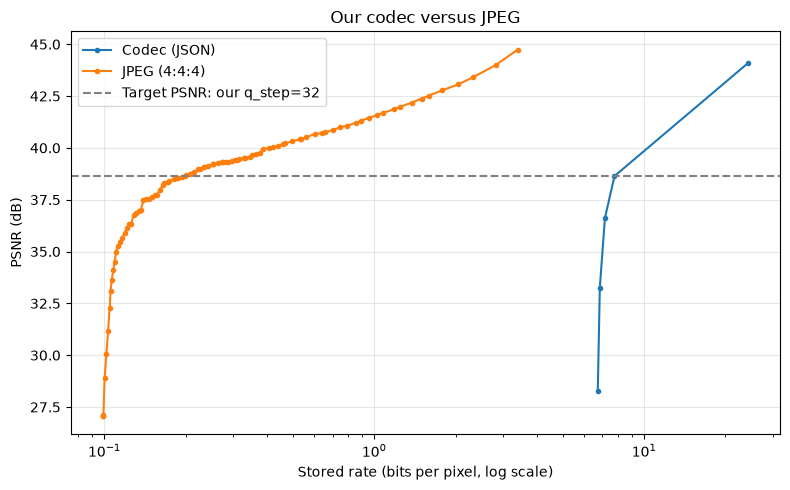

In [127]:
plt.figure(figsize=(8, 5))

for name, measurements in [
    ("Codec (JSON)", stats),
    ("JPEG (4:4:4)", jpeg_stats),
]:
    ordered = sorted(
        measurements,
        key=lambda result: result["bits_per_pixel"],
    )

    plt.plot(
        [result["bits_per_pixel"] for result in ordered],
        [result["psnr"] for result in ordered],
        ".-",
        label=name,
    )

plt.axhline(
    target_psnr,
    color="gray",
    linestyle="--",
    label=f"Target PSNR: our q_step={q_step}",
)

plt.xscale("log")
plt.xlabel("Stored rate (bits per pixel, log scale)")
plt.ylabel("PSNR (dB)")
plt.title("Our codec versus JPEG")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

We can observe that JPEG pipeline performs better than our Codec. 

Our pipeline currently stores the RLE pairs as JSON, which adds storage overhead due to text and the overall structure.

JPEG pipeline assembls the sequence obtained after zigzag and stores the zero count, depending upon the quality the block usually consists of more zeros, thus the zero-run coding skips the overhead of storing zeros. This when paired huffman encoding, gives a compact binary representation.

Also JPEG pipeline uses a quality matrix instead of single value to divide the block values, this allows more zeros in the block by dividing higher frequencies with larger values. In our pipeline, we use a single q_step value, which preserves non-zero values.



# 6. One documented failure, or a setting where your method should not be used.

As we observed in section 4, when q_step=8, the stored size actually more than the raw size.

In [128]:
# Reuse the q_step=8 result from Section 4
failure_result = next(
    result for result in stats
    if result["q_step"] == 8
)

raw_size = image_array.nbytes
stored_size = failure_result["size_bytes"]

size_change_percent = 100 * (stored_size - raw_size) / raw_size
compression_ratio = raw_size / stored_size

print("Setting: q_step=8")
print(f"Raw image size: {raw_size:,} bytes")
print(f"Stored size: {stored_size:,} bytes")
print(f"Size change against raw: {size_change_percent:+.2f}%")
print(f"Compression ratio: {compression_ratio:.2f}:1")
print(f"PSNR: {failure_result['psnr']:.2f} dB")

if stored_size > raw_size:
    print("\nFailure observed: encoding increases the storage required.")
else:
    print("\nStorage expansion was not observed in this run.")

Setting: q_step=8
Raw image size: 3,000,000 bytes
Stored size: 3,024,222 bytes
Size change against raw: +0.81%
Compression ratio: 0.99:1
PSNR: 44.08 dB

Failure observed: encoding increases the storage required.


Thus, we can observe that when q_step setting is set 8, the size of compressed file is larger than the size of original raw image. 

Setting the quantisation step, keeps more non-zero coefficients, and since we use RLE, the storage sequence becomes large.

Thus this codec is ideal to apply where lossy compressions are acceptable. However if one wants to preserve the image quality, it can be expensive to store using this pipeline. Given our images are related to industry defects, the image quality cannot be compromised a lot for the sake of storage. As future work we would like to implement Huffman method for entropy encoding. Similarly, in order to preserve image structure and we would like to implement methods such as PCA for image transformation.

# 7. Run instructions, fixed seeds, who did what, and the generative-AI declaration.
Run instructions:

Fixed seeds:

Akanksha: Contributed to implementing the codec and Sections 4, 5, 6 

Filza: Sections 

Generative-AI declaration:


## 8. Codec

Image: 192.png
Shape: (1000, 1000, 3)
Data type: uint8
Original file size: 1150859 bytes
Raw image size: 3000000 bytes


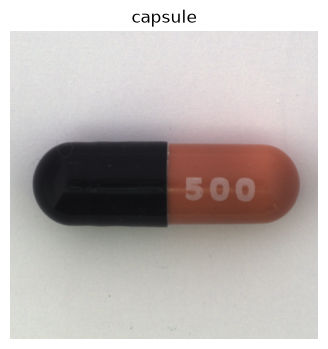

In [129]:
# Select one image for testing our codec
objecttype = "capsule"

obj = get_one_random_image(data_dict, objecttype)
imgpath = obj[0]

# Convert to RGB and NumPy array
img = Image.open(imgpath).convert("RGB")
image_array = np.array(img)

display_image(img, title=objecttype, axes=False)

print("Image:", imgpath.name)
print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Original file size:", imgpath.stat().st_size, "bytes")
print("Raw image size:", image_array.nbytes, "bytes")

### Initialize codec

Initialize the code by giving the pipeline stages.

In [130]:
codec = Codec(stages= [DCT(), Quantisation(q_steps=32), ZigZag(), RLE()])

### Apply compression

Give the image and the desired name for compressed output file

In [131]:
compressed_image = codec.compress(img, output_file="compressed_image1.json")

Encoded image saved to: compressed/compressed_image1.json


### Apply Decompression

Give the compressed image as input

In [132]:
decompressed_image = codec.decompress(compressed_image)

<Axes: title={'center': 'capsule'}>

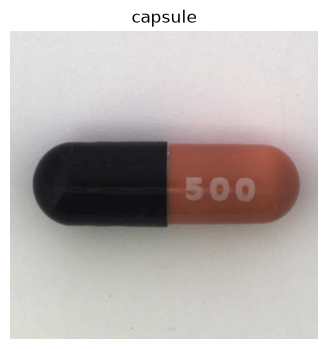

In [133]:
display_image(decompressed_image, title=objecttype, axes=False)
